# Código Cristalizador SQM
### ¿Qué tiene que resolver el código?

Un cristalizador evaporativo MSMPR se describe con tres balances acoplados:

- Balance de población (PBE): cómo cambia la distribución de tamaños n(L,t) por crecimiento, nucleación y descarga del producto. Es una EDP. Al dividir el eje de tamaños en celdas (volúmenes finitos) se convierte en un sistema de EDOs.
- Balance de masa de soluto y de solvente: el KNO₃ que pasa de la solución al cristal, y el agua que sale como vapor. Aquí entra la evaporación.
- Balance de energía: el calor que se entrega, el que se va en evaporar agua y el calor de cristalización.

En resumen: un sistema grande de EDOs, propiedades termodinámicas (solubilidad, presión de vapor, calor latente), datos de planta para comparar y gráficos. 

### 1. Importamos librerías necesarias

In [1]:
# =========================================================
# 0. Librerías
# =========================================================
# Biblioteca estándar
from dataclasses import dataclass, field   # parámetros ordenados y con nombre
import copy                                 # duplicar casos para sensibilidad

# Cálculo numérico
import numpy as np                          # vectores: n(L), flujos, momentos
from scipy.integrate import solve_ivp       # integrador de EDOs (rígido: BDF/LSODA)
from scipy.optimize import brentq, least_squares  # ec. algebraicas y ajuste de parámetros

# Datos y gráficos
import pandas as pd                         # lectura de los Excel de SQM (requiere openpyxl)
import matplotlib.pyplot as plt             # CSD, trayectorias, diagnósticos

# Verificación rápida de versiones (útil para reproducibilidad del informe)
import scipy, matplotlib
print("numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

numpy 1.26.0 | scipy 1.16.3 | pandas 3.0.1 | matplotlib 3.10.8


## 2. Termodinámica del sistema KNO₃–KClO₄ en la salmuera de SQM

Esta sección define **todo lo que el resto del modelo necesita saber del equilibrio sólido–líquido**: cuánto KNO₃ y cuánto KClO₄ caben en el licor a cada temperatura, y cómo eso cambia con el Mg y el NaNO₃. El resto del código (balances, PBE, perclorato en el cristal) solo llama a las funciones que se definen aquí, de modo que la sobresaturación queda definida **en un único lugar**.

**Ruta de cálculo (paso a paso):**

1. Curvas de solubilidad de KNO₃ y KClO₄ en **agua pura**, ajustadas a datos de bibliografía con la ecuación de Apelblat (modelo empírico ampliamente utilizado en química e ingeniería química para correlacionar y predecir la solubilidad de solutos sólidos en disolventes líquidos (puros o mezclas) en función de la temperatura).
2. Producto de solubilidad aparente de cada sal, $K'_{sp}(T) = m_{sat}(T)^2$ (sales 1:1).
3. Extensión a la salmuera con **efecto de ion común** (el K⁺ y el NO₃⁻ son compartidos) y un **factor de actividad** $\Gamma$ que corrige la no idealidad de la mezcla.
4. Calibración de $\Gamma_{KClO_4}$ con el ensayo de SQM sobre SSKd.
5. Sobresaturación única, índice de saturación del KClO₄ y holgura térmica.

**Convención de unidades.** Dentro de esta sección las concentraciones se expresan en **molalidad** (mol por kg de agua). Es la base natural para un cristalizador evaporativo: cuando se evapora agua, la molalidad de las especies que no cristalizan sube en proporción directa, sin depender de la densidad del licor.

In [2]:
# =========================================================
# 2.1 Constantes y datos de bibliografía (agua pura)
# =========================================================
R_GAS = 8.314            # J/(mol K)
M = {"KNO3": 101.10, "KClO4": 138.55, "K": 39.10, "NO3": 62.00,
     "ClO4": 99.45, "Mg": 24.305, "Na": 22.99, "NaNO3": 84.99}   # g/mol

# Solubilidad de KNO3 en agua [g KNO3 / 100 g H2O].
# Fuente: base de datos chemister.ru (KNO3, id 513), valores coincidentes con tablas escolares
# derivadas del CRC (31,6 / 45,8 / 63,9 g a 20 / 30 / 40 °C). VERIFICAR contra Perry o CRC antes del informe.
SOL_KNO3_AGUA = pd.DataFrame({
    "T_C":      [10,   20,   25,   30,   40,   60,    80,    100],
    "g_100g":   [21.2, 31.6, 37.9, 46.0, 63.9, 110.1, 168.8, 243.6]})

# Solubilidad de KClO4 en agua [g KClO4 / 100 mL H2O ~ g / 100 g H2O].
# Fuentes: chemister.ru (KClO4, id 519) y hoja de seguridad J.T. Baker, compilados en Wikipedia
# (0, 25, 40 y 100 °C); 17 g/L a 20 °C de la ficha Merck/ChemicalBook.
# OJO: los puntos de 20, 25 y 40 °C no son del todo consistentes entre sí (ver residuos del ajuste).
# Pendiente: reemplazar por una tabla única (Linke & Seidell o CRC).
SOL_KCLO4_AGUA = pd.DataFrame({
    "T_C":    [0,    20,  25,  40,   100],
    "g_100g": [0.76, 1.7, 1.5, 4.76, 21.08]})

def g100_a_molal(g_100g, sal):
    """g de sal / 100 g agua -> mol/kg agua."""
    return np.asarray(g_100g) * 10.0 / M[sal]

display(SOL_KNO3_AGUA.T, SOL_KCLO4_AGUA.T)

,0,1,2,3,4,5,6,7
T_C,10.0,20.0,25.0,30.0,40.0,60.0,80.0,100.0
g_100g,21.2,31.6,37.9,46.0,63.9,110.1,168.8,243.6


,0,1,2,3,4
T_C,0.00,20.0,25.0,40.00,100.00
g_100g,0.76,1.7,1.5,4.76,21.08


### 2.2 Ajuste de las curvas binarias (ecuación de Apelblat)

La ecuación de Apelblat es una forma estándar y con base termodinámica para la solubilidad de sólidos en función de la temperatura:

$$\ln m_{sat}(T) = A + \frac{B}{T} + C\,\ln T \qquad (T \text{ en K})$$

El término $B/T$ viene de la ecuación de van't Hoff (entalpía de disolución) y $C \ln T$ permite que esa entalpía cambie con la temperatura. Se ajusta en escala logarítmica para que todos los puntos pesen en error relativo.

KNO3: A=108.242, B=-7510.7, C=-14.3428 | error relativo máx = 1.2 %
KClO4: A=16.736, B=-3820.8, C=-1.0216 | error relativo máx = 38.2 %


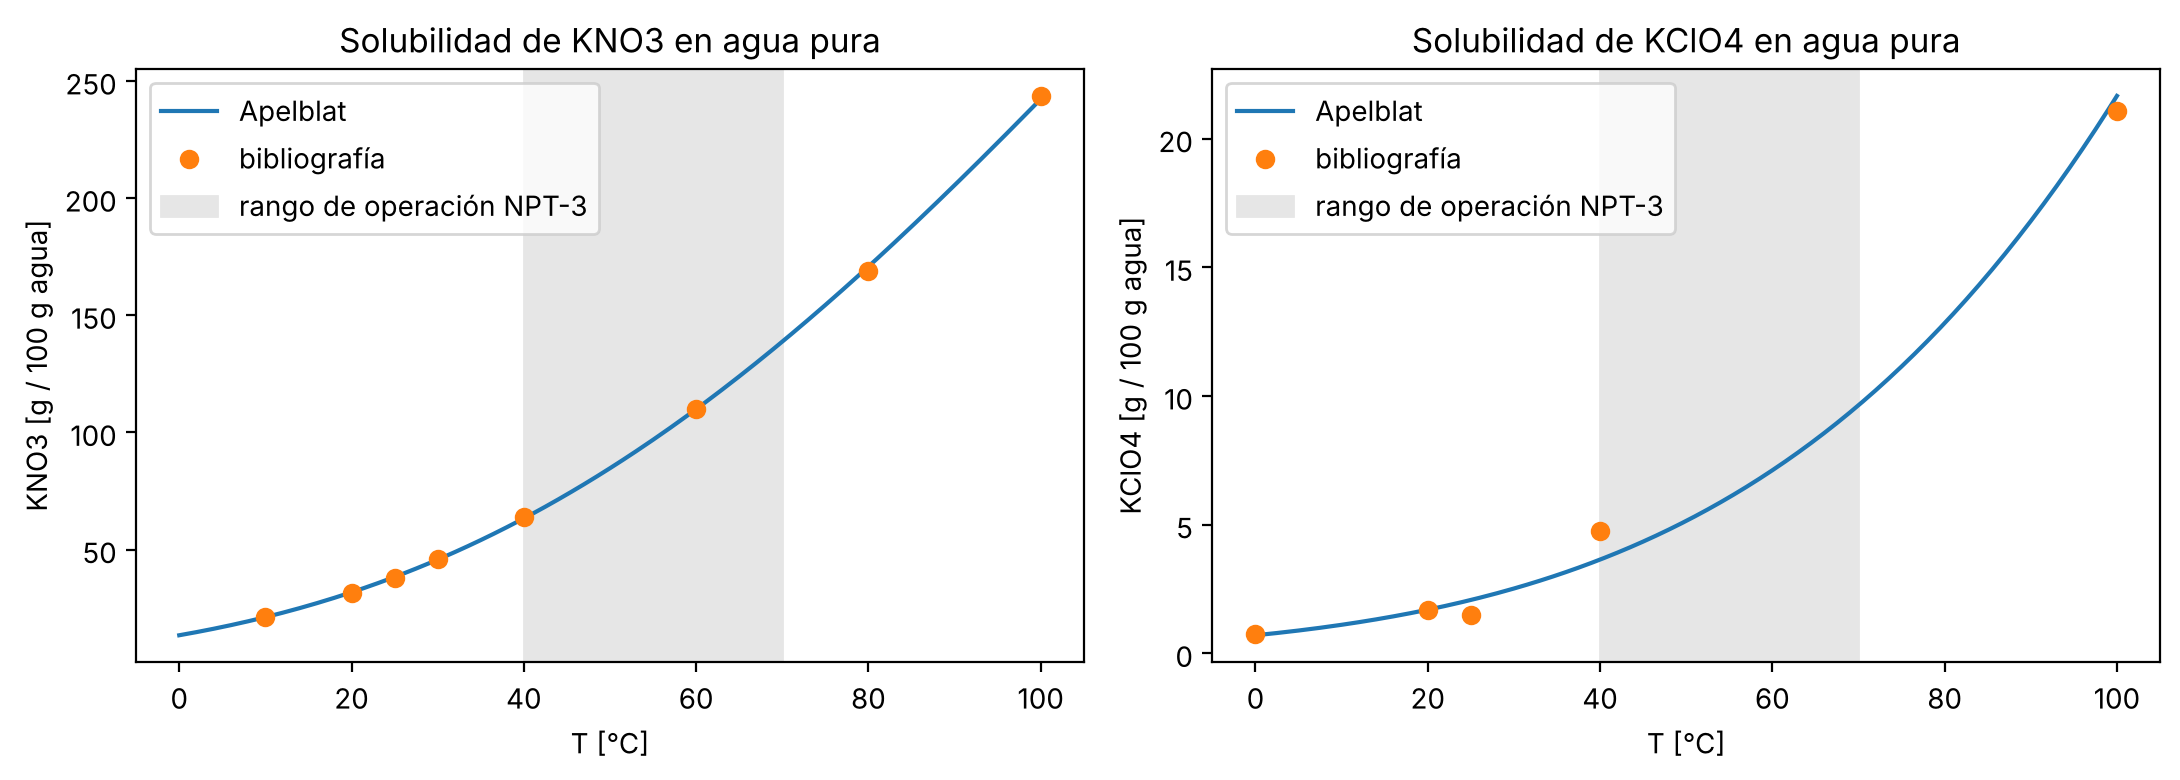

In [3]:
def apelblat(p, T_C):
    TK = np.asarray(T_C, dtype=float) + 273.15
    return np.exp(p[0] + p[1] / TK + p[2] * np.log(TK))

def ajustar_apelblat(T_C, m):
    res = least_squares(lambda p: np.log(apelblat(p, T_C)) - np.log(m), x0=[0.0, -1000.0, 0.0])
    return res.x, res.fun        # parámetros y residuos en ln(m)

P_APEL = {}
for sal, tabla in (("KNO3", SOL_KNO3_AGUA), ("KClO4", SOL_KCLO4_AGUA)):
    m_dat = g100_a_molal(tabla["g_100g"], sal)
    P_APEL[sal], resid = ajustar_apelblat(tabla["T_C"].values, m_dat)
    print(f"{sal}: A={P_APEL[sal][0]:.3f}, B={P_APEL[sal][1]:.1f}, C={P_APEL[sal][2]:.4f} | "
          f"error relativo máx = {100*np.max(np.abs(np.expm1(resid))):.1f} %")

def m_sat_agua(sal, T_C):
    """Solubilidad en agua pura [mol/kg agua]."""
    return apelblat(P_APEL[sal], T_C)

def Ksp_ap(sal, T_C):
    """Producto de solubilidad aparente de una sal 1:1 en agua pura: K'sp = m_sat^2 [(mol/kg)^2].
    Absorbe los coeficientes de actividad del sistema binario saturado."""
    return m_sat_agua(sal, T_C) ** 2

# Gráfico de verificación
Tg = np.linspace(0, 100, 201)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (sal, tabla) in zip(ax, (("KNO3", SOL_KNO3_AGUA), ("KClO4", SOL_KCLO4_AGUA))):
    a.plot(Tg, m_sat_agua(sal, Tg) * M[sal] / 10, label="Apelblat")
    a.plot(tabla["T_C"], tabla["g_100g"], "o", label="bibliografía")
    a.axvspan(40, 70, color="0.9", label="rango de operación NPT-3")
    a.set(xlabel="T [°C]", ylabel=f"{sal} [g / 100 g agua]", title=f"Solubilidad de {sal} en agua pura")
    a.legend()
plt.tight_layout(); plt.show()

### 2.3 Extensión a la salmuera: ion común y factor de actividad

En el licor de SQM el K⁺ está compartido por el KNO₃ y el KClO₄, y el NO₃⁻ también aporta el NaNO₃ y el Mg(NO₃)₂. Para una sal 1:1 la condición de saturación es

$$m_{K^+}\, m_{X^-} = \Gamma_X \, K'_{sp,X}(T), \qquad X \in \{NO_3^-,\ ClO_4^-\}$$

- $K'_{sp,X}(T)$ es el producto aparente del sistema binario (sección 2.2).
- $\Gamma_X$ corrige la diferencia de coeficientes de actividad entre la salmuera y el binario saturado. Con $\Gamma = 1$ queda el **efecto de ion común ideal**.
- Para el efecto del Mg se usa una corrección empírica: $\ln\Gamma_X = \ln\Gamma_{X,0} + k_{X,Mg}\,(m_{Mg} - m_{Mg,ref})$.

**Consecuencias que salen del propio modelo (sin parámetros extra):**

- Como el licor tiene mucho K⁺ (KNO₃ casi saturado), la solubilidad del KClO₄ es **mucho menor que en agua pura**.
- Si baja el NaNO₃, baja el exceso de nitrato, la sal KNO₃ admite más K⁺ disuelto y, por ion común, **baja la solubilidad del KClO₄**. Es justo lo que reportó SQM.
- El Mg aporta nitrato (lo que por sí solo subiría la solubilidad del KClO₄), pero SQM observa lo contrario. Por eso el efecto del Mg **tiene que entrar por $k_{ClO_4,Mg} < 0$** y calibrarse con datos.

**Sobresaturación única.** Para una sal 1:1 se define

$$S_X = \sqrt{\frac{m_{K^+}\, m_{X^-}}{\Gamma_X\, K'_{sp,X}(T)}}, \qquad \sigma_X = S_X - 1$$

En agua pura se reduce a $\sigma = m/m_{sat} - 1 = \Delta C/C^*$, la misma definición del modelo anterior, así que es compatible con las cinéticas de bibliografía. **Todo el código usa `sobresaturacion()`**; ninguna otra función calcula σ por su cuenta.

In [4]:
# =========================================================
# 2.3 Funciones de equilibrio en la salmuera
# =========================================================
# Parámetros de actividad. Procedencia: 'calibrado' / 'supuesto' / 'pendiente'.
TERMO = {
    "lnGamma0": {"KNO3": 0.0, "KClO4": 0.0},          # se calibra KClO4 en 2.5; KNO3 pendiente (datos de MLK)
    "k_Mg":     {"KNO3": 0.0, "KClO4": 0.0},          # [kg/mol] pendiente: requiere ensayos a distinto Mg
    "m_Mg_ref": 2.0,                                  # [mol/kg] referencia del ajuste (≈ Mg del ensayo SQM)
}
PROCEDENCIA_TERMO = {"lnGamma0.KNO3": "pendiente (MLK)", "lnGamma0.KClO4": "calibrado en 2.5",
                     "k_Mg.KNO3": "pendiente", "k_Mg.KClO4": "pendiente (signo esperado < 0)"}

def Gamma(sal, m_Mg, termo=TERMO):
    return np.exp(termo["lnGamma0"][sal] + termo["k_Mg"][sal] * (m_Mg - termo["m_Mg_ref"]))

def sobresaturacion(sal, T_C, comp, termo=TERMO):
    """ÚNICA definición de sobresaturación del modelo.
    comp: dict con molalidades [mol/kg agua] de 'K', 'NO3', 'ClO4', 'Mg'.
    Devuelve sigma = S - 1, con S = sqrt(IAP / (Gamma * K'sp)). sigma < 0 significa subsaturado."""
    anion = {"KNO3": "NO3", "KClO4": "ClO4"}[sal]
    IAP = comp["K"] * comp[anion]
    return np.sqrt(IAP / (Gamma(sal, comp["Mg"], termo) * Ksp_ap(sal, T_C))) - 1.0

def m_K_eq_KNO3(T_C, comp, termo=TERMO):
    """K+ disuelto [mol/kg] cuando el licor está en equilibrio con KNO3 sólido.
    Al cristalizar x mol/kg de KNO3 se pierde lo mismo de K+ y de NO3-: el exceso d = NO3 - K se conserva."""
    d = comp["NO3"] - comp["K"]
    Kp = Gamma("KNO3", comp["Mg"], termo) * Ksp_ap("KNO3", T_C)
    return 0.5 * (-d + np.sqrt(d * d + 4.0 * Kp))

def m_ClO4_sat(T_C, m_K, m_Mg, termo=TERMO):
    """Solubilidad del perclorato [mol/kg] para un K+ dado (ion común)."""
    return Gamma("KClO4", m_Mg, termo) * Ksp_ap("KClO4", T_C) / m_K

### 2.4 Composición del licor de alimentación (SSK / SSKd)

Se usan las medianas de los análisis químicos de SQM (`AQ SSKd.xlsx`, octubre 2026, 356 muestras de SSK y 180 de SSKd). Se interpretan como **g/L de solución**, con NO₃ total informado también como "NaNO₃ equivalente" (681 × 62/85 ≈ 497, que coincide con la columna NO₃).

Para pasar de g/L a mol/kg de agua hace falta **cuánta agua hay en un litro de licor** ($w_{agua}$). Ese dato no está en los análisis, así que queda como **supuesto explícito**: 0,55 kg/L (licor de ~1,5 kg/L con ~1 kg/L de sales disueltas). Medir la densidad y la humedad del SSKd elimina este supuesto.

⚠ **Unidades por confirmar con SQM.** Además, los cationes medidos superan a los aniones medidos en ~4,4 eq/L. Lo más probable es que sea cloruro no analizado (NaCl/KCl arrastrado desde conversión), y eso también hay que confirmarlo.

In [5]:
# Medianas AQ SSKd.xlsx (oct-2026) [g/L]
LICOR_GL = {
    "SSK":  {"K": 251.0, "NO3": 503.0, "Mg": 28.8, "Na": 86.0, "ClO4": 4.4},
    "SSKd": {"K": 223.5, "NO3": 607.5 * M["NO3"] / M["NaNO3"], "Mg": 27.1, "ClO4": 4.1},
}
# Mg de SSKd = 27,1 g/L (muestra del ensayo de SQM); ClO4 de SSKd = 5,7 g/L KClO4 del ensayo -> 4,1 g/L ClO4.
W_AGUA_KG_L = 0.55       # SUPUESTO: kg de agua por L de licor (medir densidad y humedad)

def gL_a_molal(comp_gL, w_agua=W_AGUA_KG_L):
    return {k: v / M[k] / w_agua for k, v in comp_gL.items()}

COMP = {n: gL_a_molal(c) for n, c in LICOR_GL.items()}
display(pd.DataFrame(COMP).round(3).rename_axis("mol/kg agua"))

# Balance de cargas del SSK (meq/L) para detectar iones no analizados
z = {"K": 1, "Na": 1, "Mg": 2, "NO3": -1, "ClO4": -1}
q = {k: z[k] * v / M[k] for k, v in LICOR_GL["SSK"].items()}
print(f"Desbalance de carga SSK = {sum(q.values()):.2f} eq/L (positivo = faltan aniones; ¿Cl-?)")

,SSK,SSKd
mol/kg agua,,
K,11.672,10.393
NO3,14.751,12.996
Mg,2.154,2.027
Na,6.801,NaN
ClO4,0.080,0.075


Desbalance de carga SSK = 4.37 eq/L (positivo = faltan aniones; ¿Cl-?)


### 2.5 Calibración de $\Gamma_{KClO_4}$ con el ensayo de SQM

El ensayo enfrió SSKd (≈ 27,1 g/L de Mg y 5,7 g/L de KClO₄) desde 74 °C y midió el KClO₄ disuelto. Bajo ~40 °C el licor está saturado en **ambas** sales, así que en cada punto:

1. el K⁺ disuelto es el que deja el KNO₃ en equilibrio (`m_K_eq_KNO3`);
2. el ClO₄⁻ disuelto es el de saturación para ese K⁺ (`m_ClO4_sat`).

Con los puntos de 25, 30 y 35 °C se ajusta **un solo parámetro**, $\ln\Gamma_{KClO_4,0}$. El punto de 40 °C es la inflexión y queda **fuera del ajuste**, porque ahí el licor apenas está llegando a saturación. Los puntos sobre 40 °C son licor subsaturado y sirven para verificar que el modelo prediga $\sigma < 0$.

Que un **único** $\Gamma$ constante reproduzca la pendiente con la temperatura es una prueba de que el mecanismo de ion común captura la física.

ln Γ_KClO4,0 = 1.677  (Γ = 5.35); error relativo máx. en 25–35 °C = 3.0 %


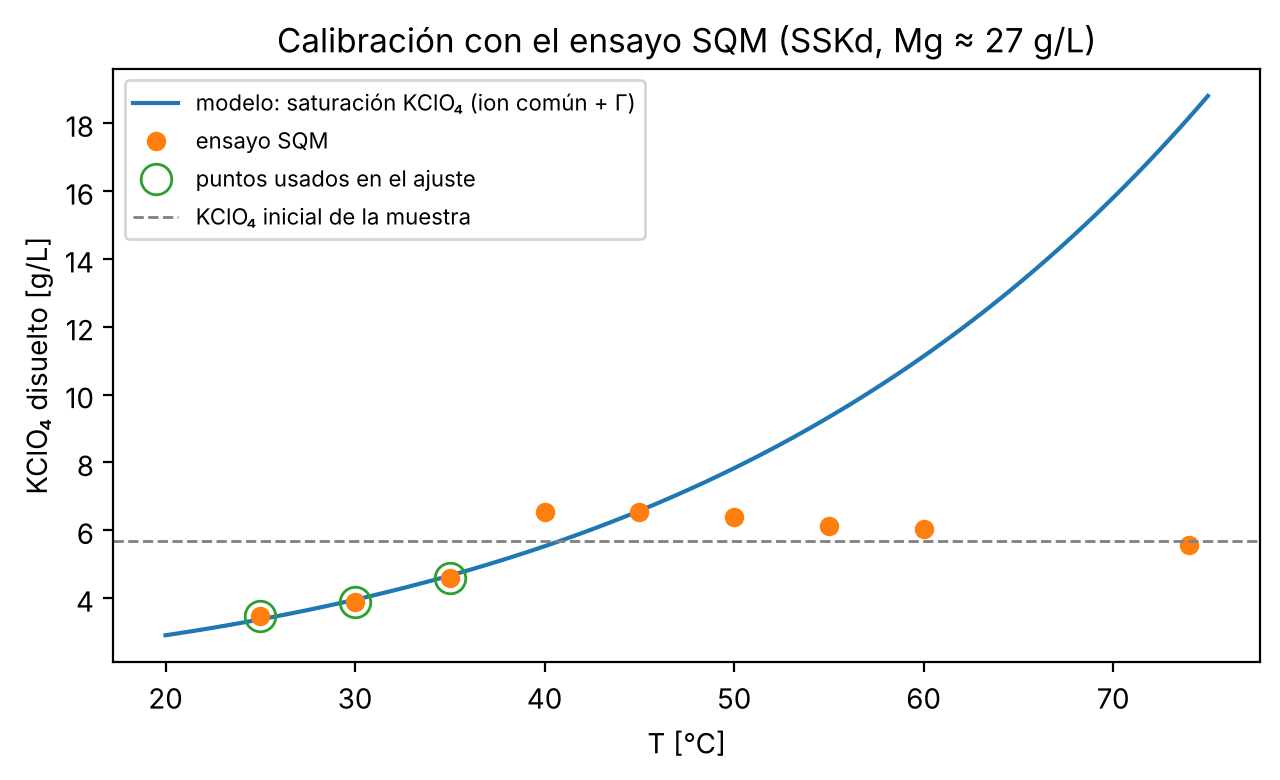

In [6]:
ENSAYO_SQM = pd.DataFrame({            # Informaciones Varias.docx, SQM
    "T_C":       [74,   60,   55,   50,   45,   40,   35,   30,   25],
    "KClO4_g_L": [5.57, 6.05, 6.12, 6.40, 6.54, 6.54, 4.59, 3.90, 3.48]})
saturado = ENSAYO_SQM["T_C"] <= 35

def predecir_ensayo(T_C, termo=TERMO, comp0=COMP["SSKd"], w_agua=W_AGUA_KG_L):
    """g/L de KClO4 disuelto predichos (licor saturado en KNO3 y KClO4)."""
    mK = m_K_eq_KNO3(T_C, comp0, termo)
    return m_ClO4_sat(T_C, mK, comp0["Mg"], termo) * M["KClO4"] * w_agua

def _res(p):
    t = copy.deepcopy(TERMO); t["lnGamma0"]["KClO4"] = p[0]
    d = ENSAYO_SQM[saturado]
    return np.log(predecir_ensayo(d["T_C"].values, t)) - np.log(d["KClO4_g_L"].values)

fit_G = least_squares(_res, x0=[1.0])
TERMO["lnGamma0"]["KClO4"] = float(fit_G.x[0])
TERMO["m_Mg_ref"] = COMP["SSKd"]["Mg"]
print(f"ln Γ_KClO4,0 = {fit_G.x[0]:.3f}  (Γ = {np.exp(fit_G.x[0]):.2f}); "
      f"error relativo máx. en 25–35 °C = {100*np.max(np.abs(np.expm1(fit_G.fun))):.1f} %")

Tp = np.linspace(20, 75, 111)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(Tp, predecir_ensayo(Tp), label="modelo: saturación KClO₄ (ion común + Γ)")
ax.plot(ENSAYO_SQM["T_C"], ENSAYO_SQM["KClO4_g_L"], "o", label="ensayo SQM")
ax.plot(ENSAYO_SQM["T_C"][saturado], ENSAYO_SQM["KClO4_g_L"][saturado], "o", mfc="none", ms=11, label="puntos usados en el ajuste")
ax.axhline(5.7, ls="--", c="0.5", lw=1, label="KClO₄ inicial de la muestra")
ax.set(xlabel="T [°C]", ylabel="KClO₄ disuelto [g/L]", title="Calibración con el ensayo SQM (SSKd, Mg ≈ 27 g/L)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 2.6 Holgura térmica y efectos del NaNO₃ y del Mg

La **holgura térmica** es la diferencia entre la temperatura de operación y la temperatura a la que el KClO₄ empezaría a precipitar ($\sigma_{KClO_4} = 0$). Es el indicador más útil para SQM: cuántos grados le quedan al cristalizador antes de contaminar el producto con KClO₄ sólido.

Abajo se calcula para el licor en equilibrio con KNO₃ y con el ClO₄ concentrado por la evaporación. Para el **Mg** se muestran **escenarios** de $k_{ClO_4,Mg}$, porque con un solo ensayo (un solo nivel de Mg) ese parámetro **no es identificable**. Las curvas con $k \neq 0$ son ilustrativas y no son datos.

T de saturación predicha para la muestra del ensayo: 40.9 °C (ensayo: inflexión cerca de 40 °C; modelo SQM: 42,5 °C)


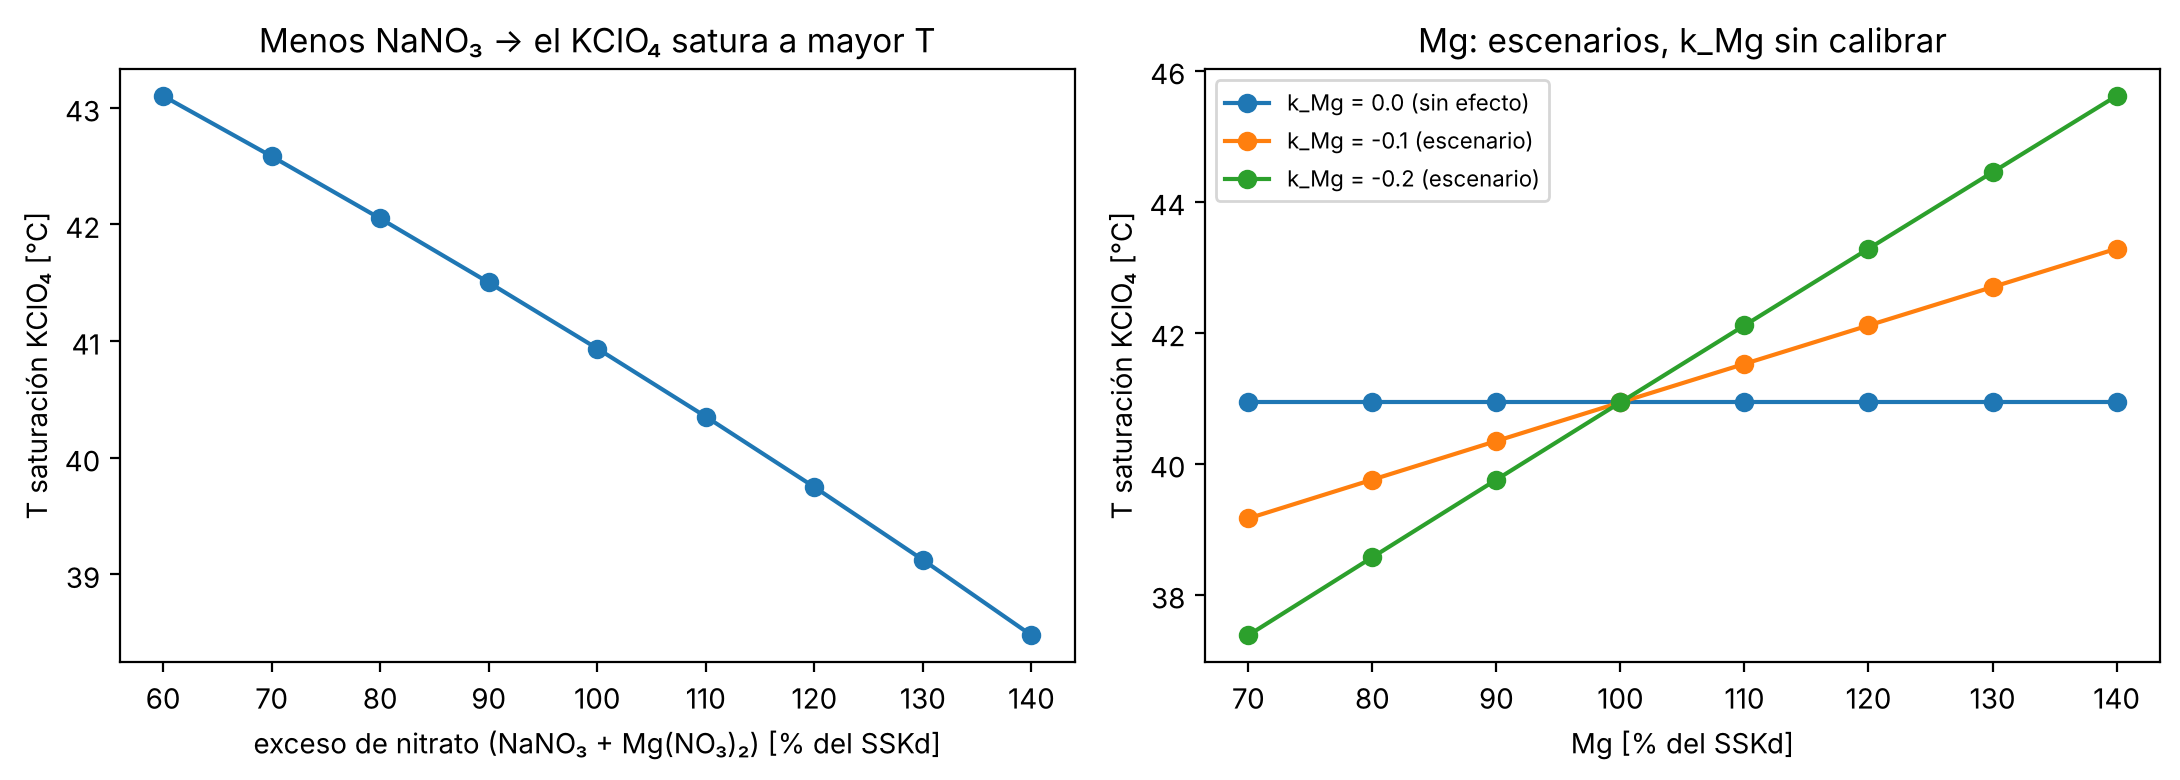

In [7]:
def T_saturacion_KClO4(comp, termo=TERMO, T_lo=5.0, T_hi=95.0):
    """T [°C] a la que sigma_KClO4 = 0 para un licor en equilibrio con KNO3 (comp: molalidades de entrada)."""
    def f(T):
        c = dict(comp); c["K"] = min(comp["K"], m_K_eq_KNO3(T, comp, termo))   # si el KNO3 está subsaturado, no cristaliza
        c["NO3"] = comp["NO3"] - (comp["K"] - c["K"])
        return sobresaturacion("KClO4", T, c, termo)
    if f(T_lo) < 0:  return np.nan     # no satura en el rango
    if f(T_hi) > 0:  return np.inf
    return brentq(f, T_lo, T_hi)

def holgura_termica(T_op, comp, termo=TERMO):
    return T_op - T_saturacion_KClO4(comp, termo)

# (a) Verificación con el ensayo: T a la que satura la muestra de SSKd
print(f"T de saturación predicha para la muestra del ensayo: {T_saturacion_KClO4(COMP['SSKd']):.1f} °C "
      "(ensayo: inflexión cerca de 40 °C; modelo SQM: 42,5 °C)")

# (b) Efecto del NaNO3 (sale del ion común, sin parámetros extra)
factores = np.linspace(0.6, 1.4, 9)
T_na = []
for f in factores:
    c = dict(COMP["SSKd"]); c["NO3"] = c["K"] + f * (COMP["SSKd"]["NO3"] - COMP["SSKd"]["K"])
    T_na.append(T_saturacion_KClO4(c))

# (c) Escenarios de Mg
mg_rel = np.linspace(0.7, 1.4, 8)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(100 * factores, T_na, "o-")
ax[0].set(xlabel="exceso de nitrato (NaNO₃ + Mg(NO₃)₂) [% del SSKd]", ylabel="T saturación KClO₄ [°C]",
          title="Menos NaNO₃ → el KClO₄ satura a mayor T")
for k in (0.0, -0.1, -0.2):
    t = copy.deepcopy(TERMO); t["k_Mg"]["KClO4"] = k
    Ts = [T_saturacion_KClO4({**COMP["SSKd"], "Mg": r * COMP["SSKd"]["Mg"]}, t) for r in mg_rel]
    ax[1].plot(100 * mg_rel, Ts, "o-", label=f"k_Mg = {k}" + (" (sin efecto)" if k == 0 else " (escenario)"))
ax[1].set(xlabel="Mg [% del SSKd]", ylabel="T saturación KClO₄ [°C]", title="Mg: escenarios, k_Mg sin calibrar")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

### 2.7 Resumen de la sección y pendientes

| Elemento | Estado | Procedencia |
|---|---|---|
| Curva KNO₃–agua (Apelblat) | ✅ | chemister.ru; verificar contra Perry/CRC |
| Curva KClO₄–agua (Apelblat) | ⚠ | datos dispersos; reemplazar por una tabla única (Linke & Seidell o CRC) |
| Sobresaturación única `sobresaturacion()` | ✅ | definición termodinámica para sal 1:1 |
| Ion común K⁺ / NO₃⁻ / ClO₄⁻ | ✅ | sin parámetros extra |
| Efecto NaNO₃ | ✅ | sale del ion común; coincide en signo con SQM |
| $\Gamma_{KClO_4,0}$ | ✅ | calibrado con el ensayo SQM (25–35 °C) |
| $\Gamma_{KNO_3,0}$ | ❌ | requiere KNO₃ en el MLK a T conocida |
| $k_{Mg}$ (KNO₃ y KClO₄) | ❌ | requiere un ensayo a otro nivel de Mg |
| $w_{agua}$ del licor | ❌ | medir densidad y humedad del SSKd |
| Unidades de AQ SSKd y Cl⁻ no analizado | ❌ | confirmar con SQM |

**Datos para pedir a SQM (agregar a la solicitud de muestreo):** densidad y contenido de agua del SSKd y del MLK; análisis de K, NO₃, Mg, Na, Cl y ClO₄ en el **MLK** de A3110 y A3210 junto con la temperatura de cada equipo (sirve para calibrar $\Gamma_{KNO_3}$); y un segundo ensayo de enfriamiento con SSKd a otro nivel de Mg (para $k_{Mg}$).